# 5_1_Forecast Ensemble
In this notebook, we explore the possibility of combining forecasts from different models / model runs. We then evaluate results and compare them against those from individual models. We first mirror the data pre-processing, then read in the results that have already been generated.

In [1]:
import pandas as pd
import numpy as np
import torch 
import os
import json

import properscoring as ps
from darts import TimeSeries, concatenate
from darts.utils.callbacks import TFMProgressBar
from darts.metrics import mape, smape, mse, rmse, mae, mql, ql
from darts.dataprocessing.transformers import Scaler
from darts.dataprocessing.transformers import StaticCovariatesTransformer
from sklearn.preprocessing import MinMaxScaler
import optuna
from optuna.samplers import TPESampler
from optuna.storages import JournalStorage
from optuna.storages.journal import JournalFileBackend
from darts.models import (
    RandomForestModel,
    LinearRegressionModel,
    XGBModel,
    TFTModel,
    TiDEModel
)
from darts.utils.likelihood_models import GaussianLikelihood, PoissonLikelihood, QuantileRegression
import matplotlib.pyplot as plt
from pytorch_lightning.callbacks import Callback, EarlyStopping
import pickle
import helpers as hp

torch.set_float32_matmul_precision("medium")
pd.options.mode.copy_on_write = True
include_stringency_index = False
accel = "gpu"

quantiles = [0.01, 0.025, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.975, 0.99]

# 1. Reading in Data

In [24]:
gpu_id = 0
tuning_name = "EnsembleTest"
random_seed = 20

#We define a boolean here, relevant to model evaluation
#If this is true, then we train a model with the tuned hyperparameters from scratch - i.e. using train1, 2, and 3. This also means that
#we can train a separate scaler on train1, which is then applied to train 1,2,3
#If this is false, then we mirror the tuning process first, training on 1a,b,c then the model will be fine tuned using train 1,2,3.
#This means that we apply the same scaler, trained only on train1a to train1a,b,c and train1,2,3. 
#train_from_scratch = False
#global_fit = True

base_dir = os.getcwd()
model_input_dir = os.path.join(base_dir, "ModelInput")
tuning_dir = os.path.join(base_dir, "Dengue Tuning", tuning_name)
vis_output_dir = os.path.join(tuning_dir, "Results")
climate_tuning_dir = os.path.join(base_dir, "Climate Tuning", "Notebook_24_07_2025")
climate_model_name = "RandomForest"
climate_forecast_dir = os.path.join(climate_tuning_dir, climate_model_name, "Forecasts")

os.makedirs(tuning_dir, exist_ok = True)
os.makedirs(vis_output_dir, exist_ok = True)
weekly_cal = pd.read_csv(os.path.join(model_input_dir, "Calendar.csv"))
weekly_cal = weekly_cal.iloc[1:]
climate_df = pd.read_csv(os.path.join(model_input_dir, "TimeVaryingCovs.csv"))
dengue_df = pd.read_csv(os.path.join(model_input_dir, "DengueCases.csv"))

#Remove uf = "ES" since there is no dengue data for Espirito Santo
climate_df = climate_df[climate_df["uf"] != "ES"]
dengue_df = dengue_df[dengue_df["uf"] != "ES"]

dengue_df = dengue_df[["epiweek", "Year", "Week", "uf", "uf_name", "Cases"]]

In [25]:
#Read the climate forecasts
clim_forecast_dict = hp.load_pickle(os.path.join(climate_forecast_dir, "forecast_dict.pkl"))
clim_forecast_log_dict = hp.load_pickle(os.path.join(climate_forecast_dir, "forecast_dict_log.pkl"))

clim_tuning_config = hp.read_json(os.path.join(climate_tuning_dir,"tuning_details.json"))
clim_var_names = clim_tuning_config["clim_var_names"]

#If boolean says we should include stringency index, then we add it into the climate variable list
if include_stringency_index:
    clim_var_names.append("StringencyIndex")

#den_tuning_config = hp.read_json(os.path.join(tuning_dir, "tuning_config.json"))

In [26]:
set_info = weekly_cal[["epiweek", "Year", "Week", "WeekStart", "WeekMid", "WeekEnd"]]

#Set up all the set information for splitting the dengue and climate data
#For tuning training 1a,b,c - val1a,b,c
set_info["den_train1a"] = set_info["epiweek"] <= 201825
set_info["den_train1b"] = set_info["epiweek"] <= 201925
set_info["den_train1c"] = set_info["epiweek"] <= 202025

set_info["den_gap1a"] = (set_info["epiweek"] >= 201826) & (set_info["epiweek"] <= 201840)
set_info["den_gap1b"] = (set_info["epiweek"] >= 201926) & (set_info["epiweek"] <= 201940)
set_info["den_gap1c"] = (set_info["epiweek"] >= 202026) & (set_info["epiweek"] <= 202040)

set_info["den_val1a"] = (set_info["epiweek"] >= 201841) & (set_info["epiweek"] <= 201940)
set_info["den_val1b"] = (set_info["epiweek"] >= 201941) & (set_info["epiweek"] <= 202040)
set_info["den_val1c"] = (set_info["epiweek"] >= 202041) & (set_info["epiweek"] <= 202140)

set_info["den_ex"] = (set_info["epiweek"] >= 202141) & (set_info["epiweek"] <= 202225)

#Train - Val - Test for model evaluation
set_info["den_train1"] = set_info["epiweek"] <= 202110
set_info["den_train2"] = set_info["epiweek"] <= 202210
set_info["den_train3"] = set_info["epiweek"] <= 202310

set_info["den_gap1"] = (set_info["epiweek"] >= 202111) & (set_info["epiweek"] <= 202125)
set_info["den_gap2"] = (set_info["epiweek"] >= 202211) & (set_info["epiweek"] <= 202225)
set_info["den_gap3"] = (set_info["epiweek"] >= 202311) & (set_info["epiweek"] <= 202325)

set_info["den_val1"] = (set_info["epiweek"] >= 202126) & (set_info["epiweek"] <= 202225)
set_info["den_val2"] = (set_info["epiweek"] >= 202226) & (set_info["epiweek"] <= 202325)
set_info["den_val3"] = (set_info["epiweek"] >= 202326) & (set_info["epiweek"] <= 202425)

#Hold sets - can be used to retrieve climate covariates for evaluation time
set_info["den_hold1"] = set_info["epiweek"] <= 202225
set_info["den_hold2"] = set_info["epiweek"] <= 202325
set_info["den_hold3"] = set_info["epiweek"] <= 202425

#Targets for model evaluation
set_info["den_targ1"] = (set_info["epiweek"] >= 202241) & (set_info["epiweek"] <= 202340)
set_info["den_targ2"] = (set_info["epiweek"] >= 202341) & (set_info["epiweek"] <= 202440)
set_info["den_targ3"] = (set_info["epiweek"] >= 202441) & (set_info["epiweek"] <= 202540)

In [27]:
uf_list = climate_df["uf"].unique()
uf_mapper = climate_df[["uf", "uf_name"]].copy().drop_duplicates()
uf_dict = dict(zip(uf_mapper["uf"], uf_mapper["uf_name"]))
uf_name_list = [uf_dict[curr_uf] for curr_uf in uf_list]

# 2. Data Preparation
We split the data again here for ease of evaluation and visusalisation.

In [6]:
#Log transformed climate (just the precipitation columns)
log_trans_cols = ["precip_min", "precip_med", "precip_max"]
proc_climate_df = hp.transform_df_cols(climate_df, log_trans_cols, np.log1p)

#Log transformed dengue cases
proc_dengue_df = hp.transform_df_cols(dengue_df, ["Cases"], np.log1p)

In [7]:
#Create all the TimeSeries objects we need for tuning first
group_col = "uf"

#Dengue case TimeSeries - without any log transforms - mostly here for visualisations and loss computations
train1a = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train1a")
train1b = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train1b")
train1c = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train1c")

val1a = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val1a")
val1b = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val1b")
val1c = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val1c")

train1 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train1")
train2 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train2")
train3 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train3")

val1 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val1")
val2 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val2")
val3 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val3")

hold1 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_hold1")
hold2 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_hold2")
hold3 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_hold3")

targ1 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_targ1")
targ2 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_targ2")
targ3 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_targ3")

## 2.1 Reading Forecast Results
Here, we read in some forecasts that we will combine in an ensemble later.

In [29]:
#results_dirs = ["GlobalFit=False_TrainFromScratch=False", "GlobalFit=True_TrainFromScratch=False"] #sets of results to load
#results_dirs = ["GlobalFit=False_TrainFromScratch=False"]
results_dirs = ["Tuning_30_07_2025", "Tuning_29_07_2025"]
#Read the predictions over the targets
targ_pred_dicts = [] #List of dictionaries containing predictions
for curr_dir in results_dirs:
    curr_filename = "Targ_" + "GlobalFit=False_TrainFromScratch=False" + ".pkl"
    loaded = hp.load_pickle(os.path.join(vis_output_dir, curr_dir, curr_filename))
    targ_pred_dicts.append(loaded)

target_keys = ["targ1_preds", "targ2_preds", "targ3_preds"]

In [30]:
def results_from_pred_dict(pred_dicts, target_keys):
    """
    Accepts a list of dictionaries, each pertaining to results from a different model, and a list
    of keys. The function then returns a list containing lists, one for each key, containing results
    across different models. 
    """
    results_per_key = []
    for curr_key in target_keys:
        builder = [curr_dict[curr_key] for curr_dict in pred_dicts]
        results_per_key.append(builder)
    return results_per_key

def restructure_results_list(curr_results_list, label_list):
    """
    Accepts a list where each element is a list of forecasts for the same time period across multiple admin units for a given model.
    This list is then restructured to return a list where each element contains forecasts across multiple models for the same admin unit
    and time period.
    """
    builder = []
    for ind in range(len(label_list)):
        curr_label_res = [curr_list[ind] for curr_list in curr_results_list]
        builder.append(curr_label_res)
    return builder

In [31]:
#Get list of results per key
results_per_key = results_from_pred_dict(targ_pred_dicts, target_keys)

#List of results per key, where each element is a list containing results per uf
preds_per_key_per_uf = [restructure_results_list(curr_results_list, uf_list) for curr_results_list in results_per_key] 

# 3. Ensemble Implementation and Evaluation
Here we implement and evaluate different ensemble methods.

## 3.1 Simple Concatenation
In simple concatenation, we just take all the samples from all models, stack them together, then base the prediction interval on that.

In [32]:
#Simple concatenation ensemble
def concat_ensemble(preds_per_uf):
    """
    Takes a list containing lists, one per admin unit, that contain forecasts across different models.
    """
    builder = []
    for curr_preds in preds_per_uf:
        builder.append(concatenate(curr_preds, axis = 2))
    return builder

## 3.2 Bootstrap Ensemble
Here, we have an alternative method of combining predictions by simply taking bootstrap samples from the forecast distribution of each model and computing the mean.

In [33]:
np.random.seed(random_seed)

def bootstrap_ensemble(preds_per_uf, num_bootstrap_samples = 500):
    #Get the number of samples in an individual forecast by 1 model for 1 admin unit
    num_preds_samples = preds_per_uf[0][0].n_samples
    
    result = []
    #For each state
    for curr_uf_preds in preds_per_uf:
        #Generate a number of indices for bootstrap sampling
        
        curr_ensemble_preds = []
        #For each bootstrap sample
        for i in range(num_bootstrap_samples):
            curr_sample_store = []
            #Generate a random index for each model in the ensemble
            sample_indices = np.random.randint(0, num_preds_samples, size = len(curr_uf_preds))
            #For each model - index pair
            for curr_model_res, curr_sample_ind in zip(curr_uf_preds, sample_indices):
                #Get the model result with the given index and add it to the sample store
                curr_vals = curr_model_res.univariate_values(sample = curr_sample_ind)
                curr_sample_ts = curr_model_res.with_values(curr_vals)
                curr_sample_store.append(curr_sample_ts)
                
            #Get the mean across modelsfrom the sample store and add it to the ensemble prediction interval
            curr_sample_mean = concatenate(curr_sample_store, axis = 2).mean()
            curr_ensemble_preds.append(curr_sample_mean)
    
        #Add the prediction distribution of the current uf to the result list
        curr_ensemble_preds_ts = concatenate(curr_ensemble_preds, axis = 2)
        result.append(curr_ensemble_preds_ts)
    return result

In [34]:
targ1_concat_ensemble = concat_ensemble(preds_per_key_per_uf[0])
targ2_concat_ensemble = concat_ensemble(preds_per_key_per_uf[1])
targ3_concat_ensemble = concat_ensemble(preds_per_key_per_uf[2])

In [35]:
targ1_bootstrap_ensemble = bootstrap_ensemble(preds_per_key_per_uf[0])
targ2_bootstrap_ensemble = bootstrap_ensemble(preds_per_key_per_uf[1])
targ3_bootstrap_ensemble = bootstrap_ensemble(preds_per_key_per_uf[2])

In [36]:
hp.generate_series_metrics_table(targ1, targ_pred_dicts[0]["targ1_preds"], uf_name_list, "uf_name", metrics = [mae, rmse, ps.crps_ensemble], metric_names = ["MAE", "RMSE", "CRPS"], normer_list = train1a, disp_mode = True)

,uf_name,Norm_MAE,Norm_RMSE,Norm_CRPS
0,Acre,0.030,0.041,0.020
1,Alagoas,0.083,0.107,0.086
2,Amazonas,0.006,0.009,0.005
3,Amapá,0.068,0.100,0.061
4,Bahia,0.091,0.108,0.056
5,Ceará,0.010,0.012,0.019
6,Distrito Federal,0.302,0.328,0.209
7,Goiás,0.051,0.060,0.049
8,Maranhão,0.041,0.056,0.032
9,Minas Gerais,0.165,0.263,0.140


In [37]:
hp.generate_series_metrics_table(targ2, targ_pred_dicts[0]["targ2_preds"], uf_name_list, "uf_name", metrics = [mae, rmse, ps.crps_ensemble], metric_names = ["MAE", "RMSE", "CRPS"], normer_list = train1a, disp_mode = True)

,uf_name,Norm_MAE,Norm_RMSE,Norm_CRPS
0,Acre,0.066,0.128,0.060
1,Alagoas,0.069,0.096,0.070
2,Amazonas,0.015,0.022,0.011
3,Amapá,0.766,0.981,0.731
4,Bahia,0.551,1.047,0.419
5,Ceará,0.044,0.063,0.034
6,Distrito Federal,3.595,6.262,3.294
7,Goiás,0.414,0.668,0.281
8,Maranhão,0.078,0.152,0.056
9,Minas Gerais,0.759,1.290,0.667


In [38]:
hp.generate_series_metrics_table(targ3, targ_pred_dicts[0]["targ3_preds"], uf_name_list, "uf_name", metrics = [mae, rmse, ps.crps_ensemble], metric_names = ["MAE", "RMSE", "CRPS"], normer_list = train1a, disp_mode = True)

,uf_name,Norm_MAE,Norm_RMSE,Norm_CRPS
0,Acre,0.124,0.151,0.100
1,Alagoas,0.023,0.032,0.022
2,Amazonas,0.007,0.008,0.005
3,Amapá,0.194,0.236,0.170
4,Bahia,0.050,0.058,0.042
5,Ceará,0.027,0.035,0.021
6,Distrito Federal,0.216,0.255,0.161
7,Goiás,0.149,0.188,0.112
8,Maranhão,0.035,0.051,0.024
9,Minas Gerais,0.072,0.086,0.055


In [39]:
hp.generate_series_metrics_table(targ1, targ_pred_dicts[0]["targ1_preds"], uf_name_list, "uf_name", metrics = [mae, rmse, ps.crps_ensemble], metric_names = ["MAE", "RMSE", "CRPS"], disp_mode = True)

,uf_name,MAE,RMSE,CRPS
0,Acre,64.109,88.173,42.529
1,Alagoas,193.762,250.883,201.108
2,Amazonas,45.272,61.110,34.558
3,Amapá,18.317,26.899,16.421
4,Bahia,581.755,692.678,356.574
5,Ceará,64.966,77.196,127.463
6,Distrito Federal,421.505,458.227,291.951
7,Goiás,449.564,532.612,429.357
8,Maranhão,78.580,106.577,61.506
9,Minas Gerais,6977.909,11132.222,5911.561


In [40]:
hp.generate_series_metrics_table(targ2, targ_pred_dicts[0]["targ2_preds"], uf_name_list, "uf_name", metrics = [mae, rmse, ps.crps_ensemble], metric_names = ["MAE", "RMSE", "CRPS"],  disp_mode = True)

,uf_name,MAE,RMSE,CRPS
0,Acre,142.382,275.183,130.383
1,Alagoas,160.535,225.985,163.877
2,Amazonas,103.129,152.410,73.539
3,Amapá,206.778,264.984,197.382
4,Bahia,3521.085,6689.532,2678.965
5,Ceará,297.591,419.734,227.703
6,Distrito Federal,5022.405,8747.832,4601.194
7,Goiás,3645.644,5882.457,2471.508
8,Maranhão,148.774,291.193,107.781
9,Minas Gerais,32174.699,54663.247,28265.944


In [41]:
hp.generate_series_metrics_table(targ3, targ_pred_dicts[0]["targ3_preds"], uf_name_list, "uf_name", metrics = [mae, rmse, ps.crps_ensemble], metric_names = ["MAE", "RMSE", "CRPS"],  disp_mode = True)

,uf_name,MAE,RMSE,CRPS
0,Acre,266.554,324.793,216.566
1,Alagoas,55.035,75.320,50.755
2,Amazonas,46.206,55.923,36.857
3,Amapá,52.312,63.783,45.946
4,Bahia,322.234,368.195,269.771
5,Ceará,183.950,232.534,137.814
6,Distrito Federal,302.122,356.090,224.525
7,Goiás,1315.097,1658.919,984.135
8,Maranhão,66.333,98.326,45.022
9,Minas Gerais,3058.193,3633.575,2323.986


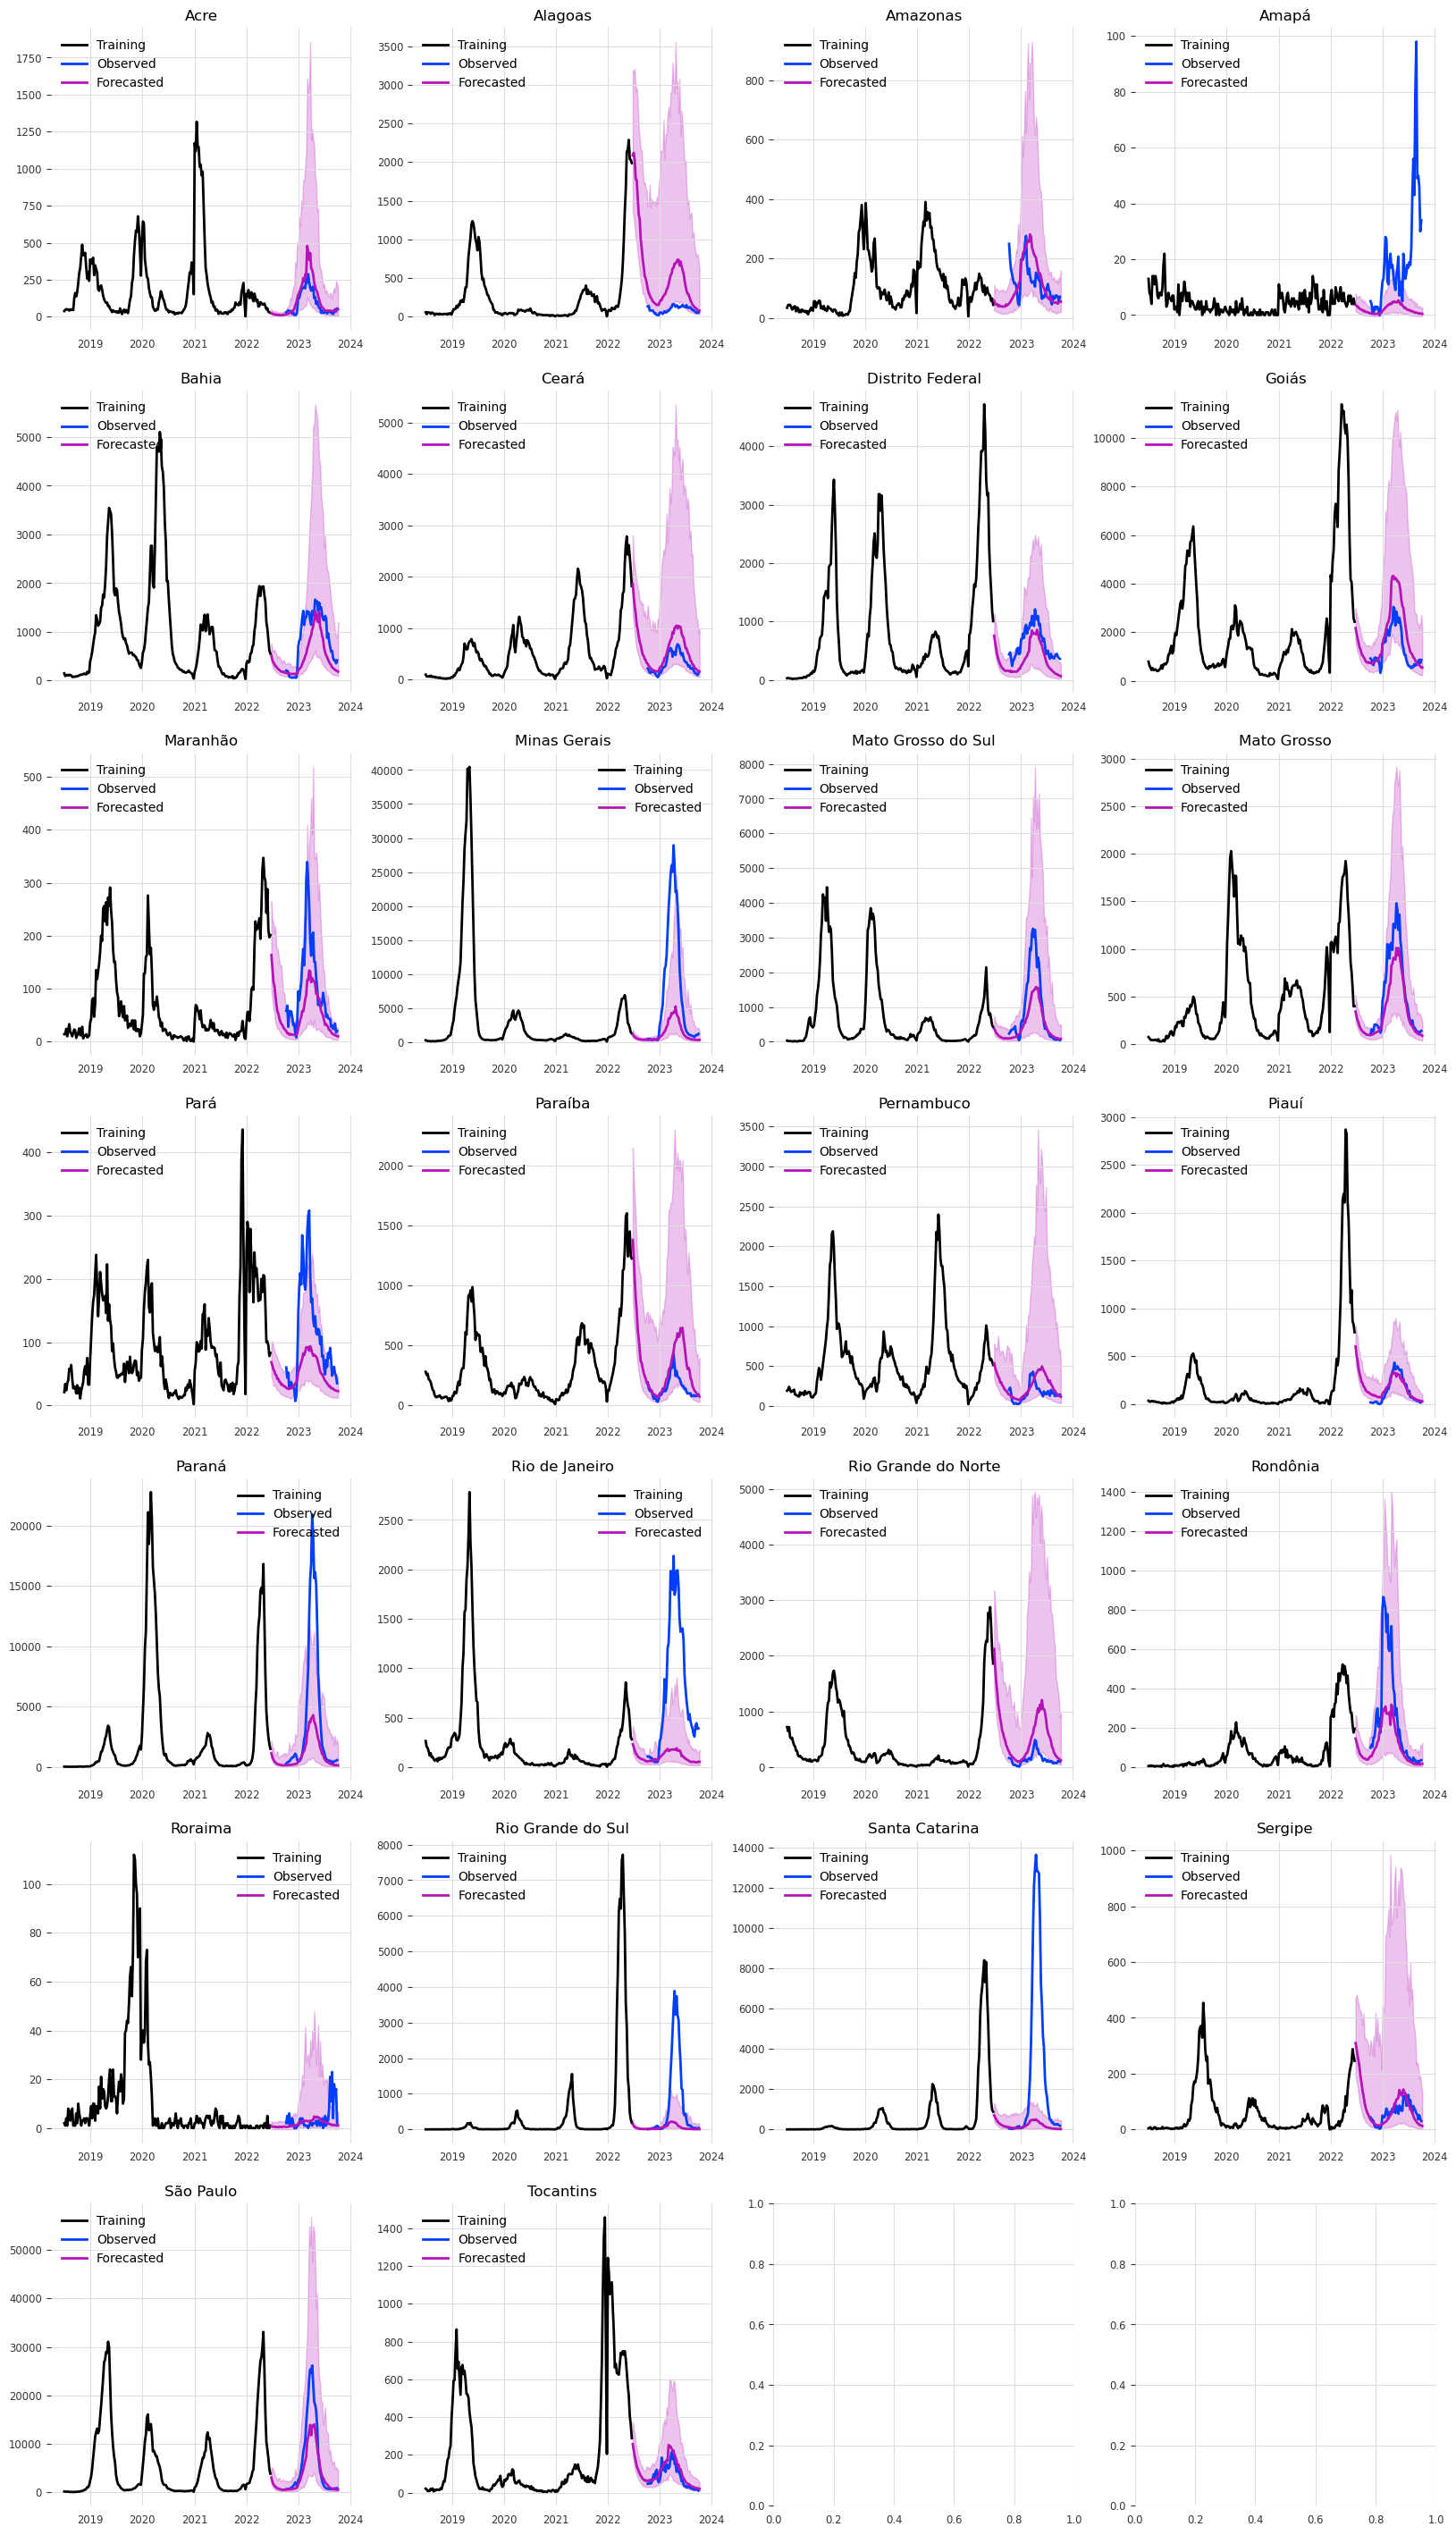

In [46]:
hp.generate_preds_obs_den_plot(hold1, targ1, targ1_bootstrap_ensemble, uf_list, uf_list, label_list = uf_name_list, train_limit = 208)

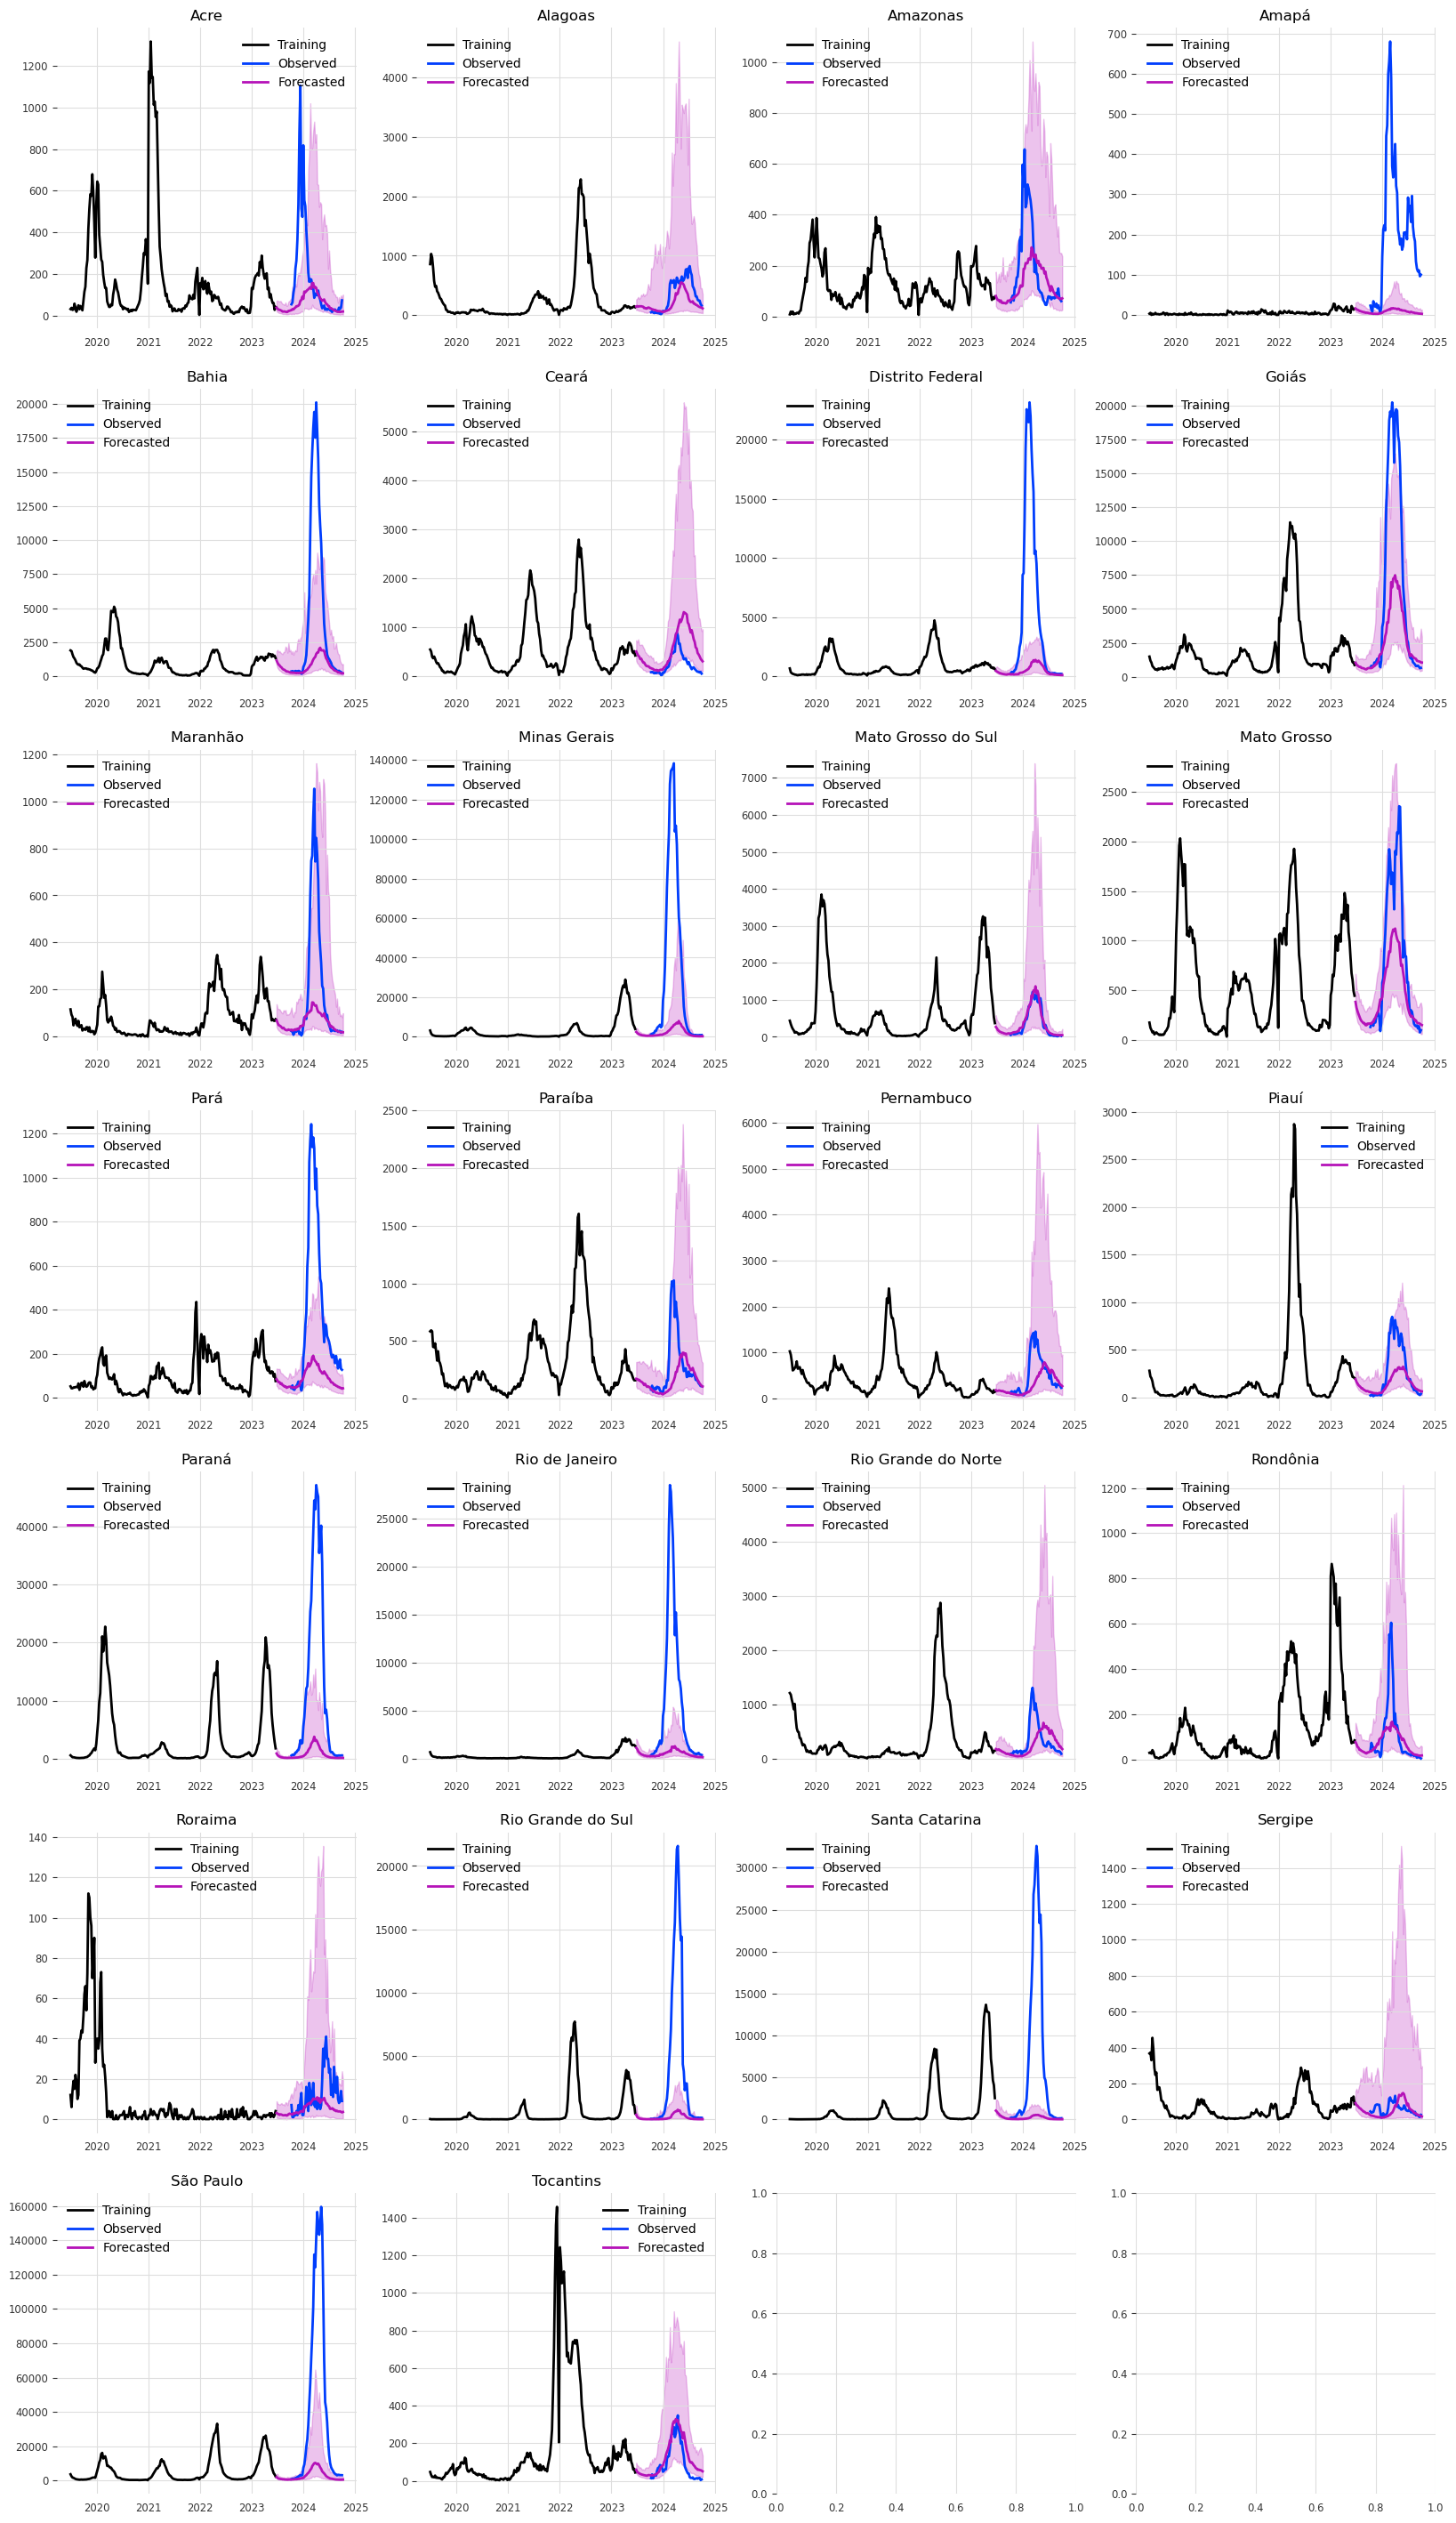

In [47]:
hp.generate_preds_obs_den_plot(hold2, targ2, targ2_bootstrap_ensemble, uf_list, uf_list, label_list = uf_name_list, train_limit = 208)

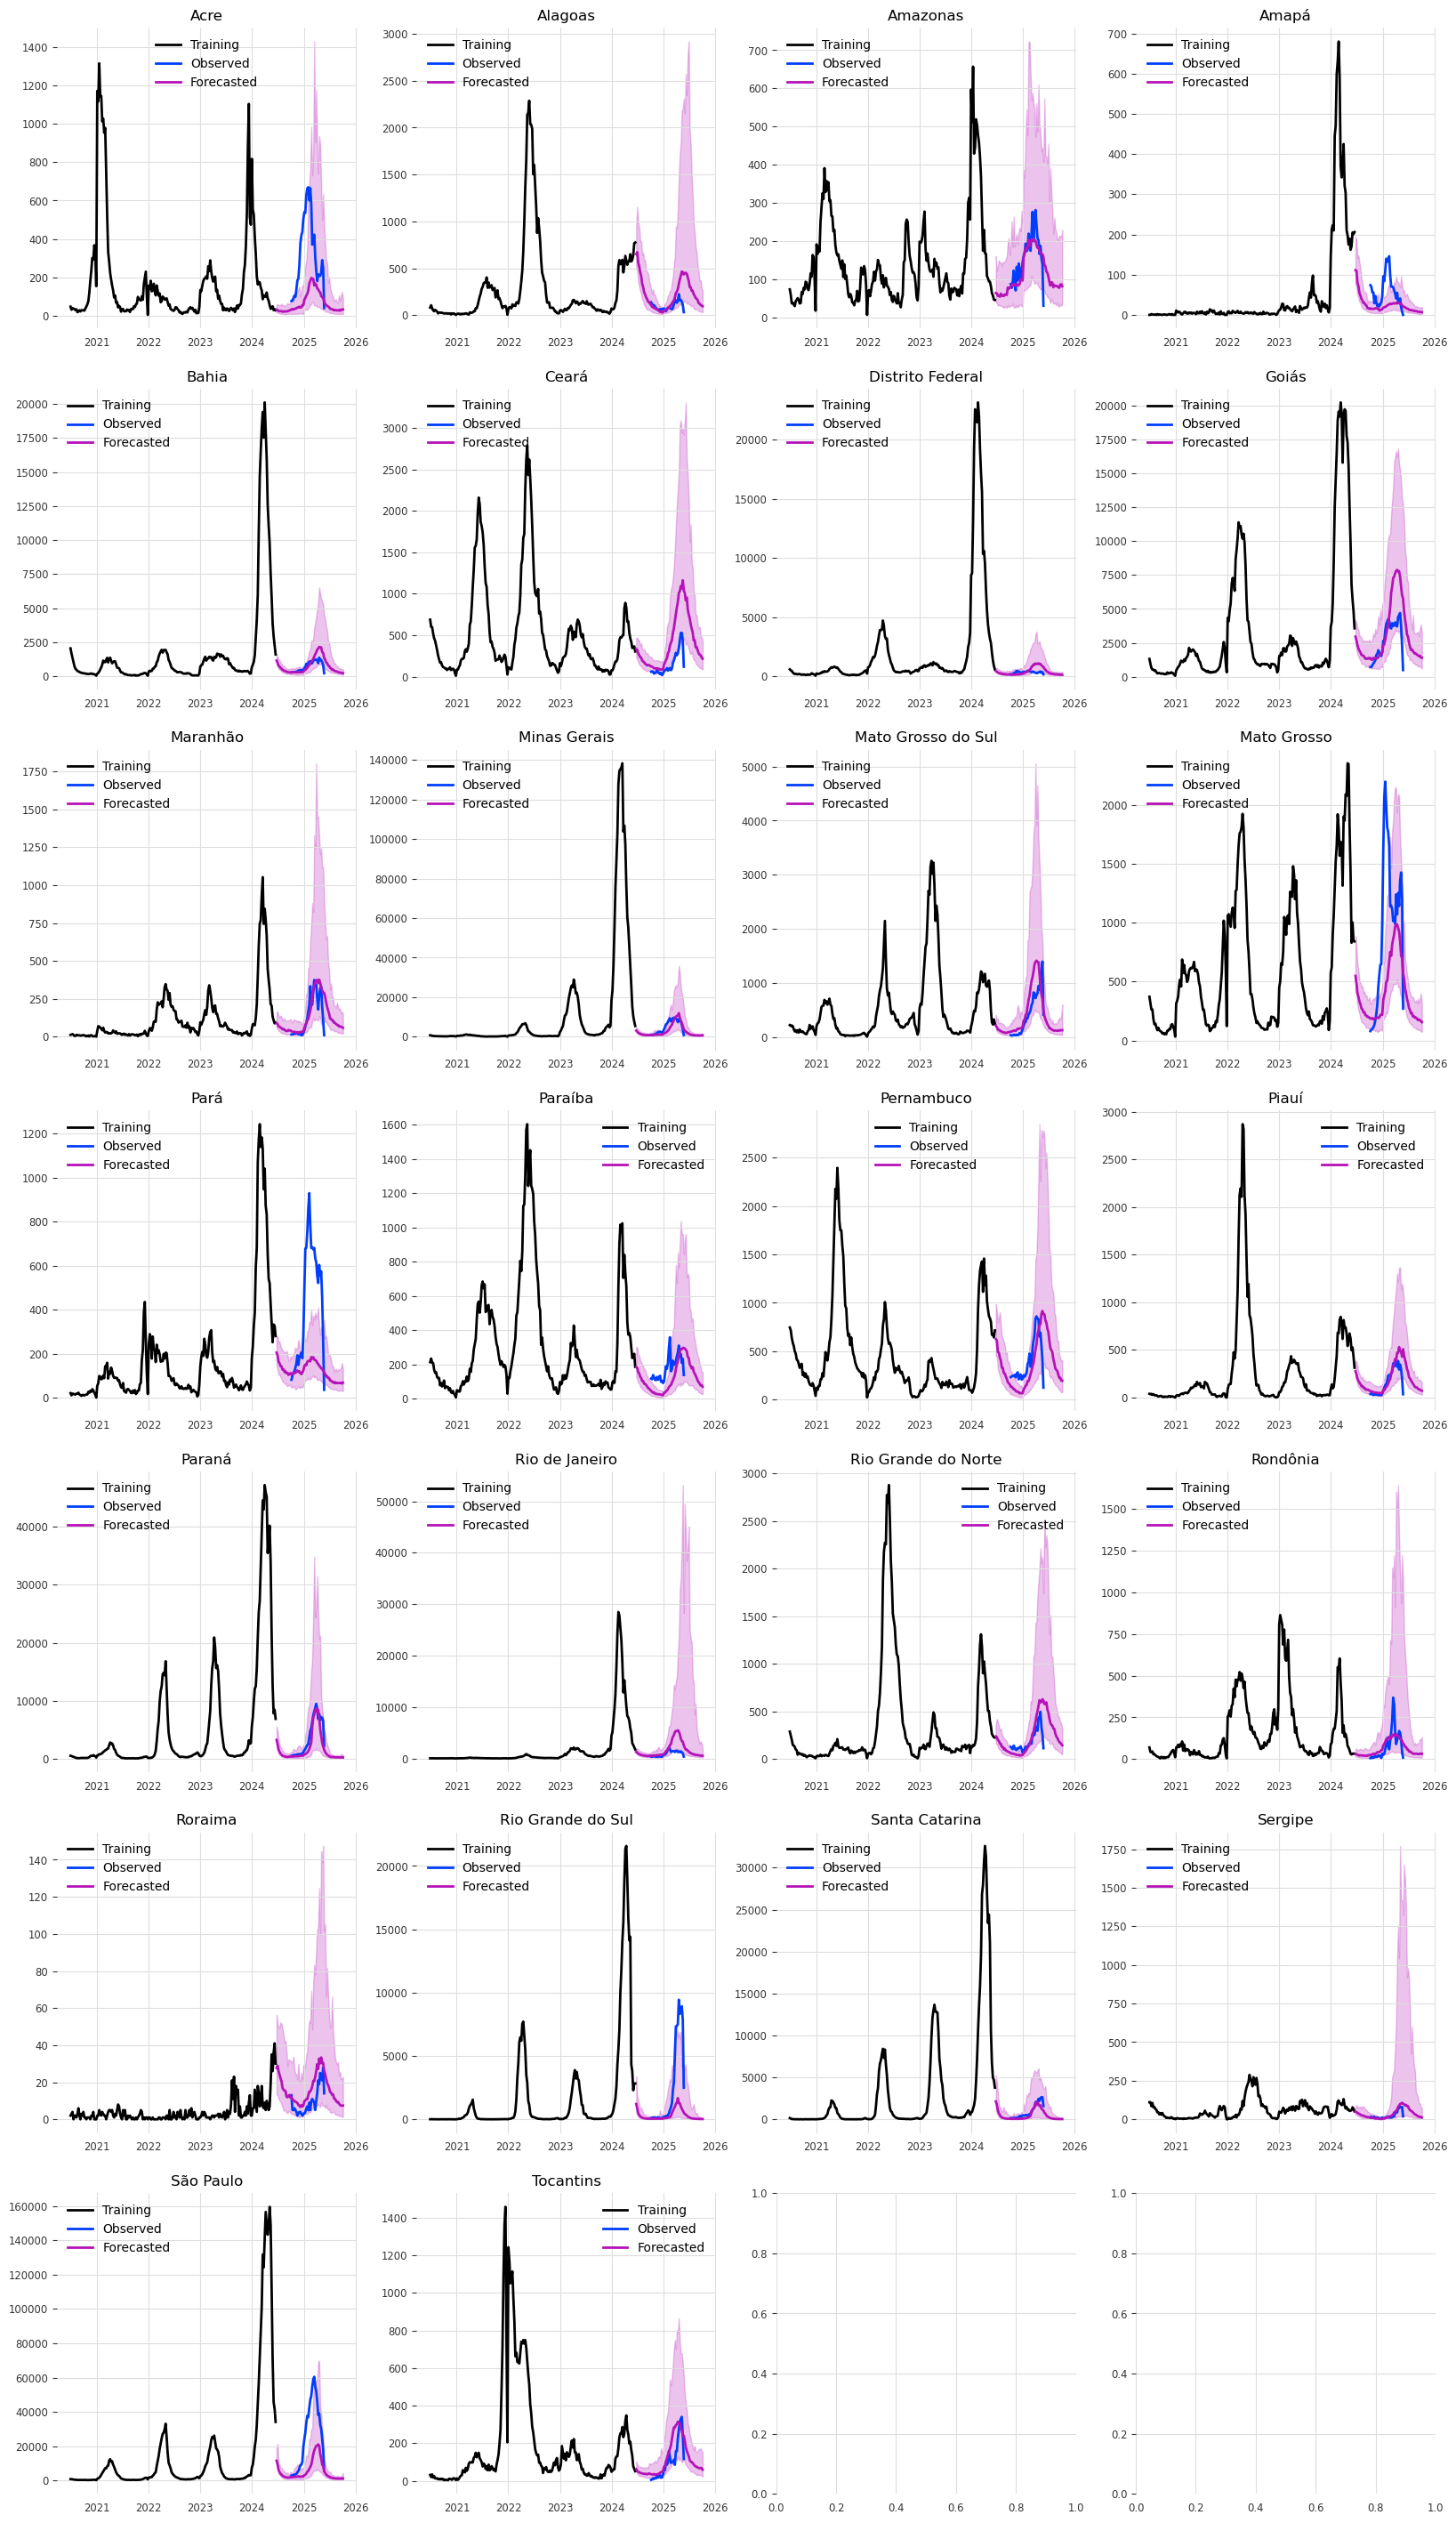

In [48]:
hp.generate_preds_obs_den_plot(hold3, targ3, targ3_bootstrap_ensemble, uf_list, uf_list, label_list = uf_name_list, train_limit = 208)

In [51]:
hp.generate_series_metrics_table(targ1, targ1_bootstrap_ensemble, uf_name_list, "uf_name", metrics = [mae, rmse, ps.crps_ensemble], metric_names = ["MAE", "RMSE", "CRPS"], disp_mode = True)

,uf_name,MAE,RMSE,CRPS
0,Acre,49.734,74.613,39.602
1,Alagoas,259.469,313.613,206.009
2,Amazonas,49.267,66.425,37.668
3,Amapá,17.888,26.679,16.625
4,Bahia,368.040,453.483,258.827
5,Ceará,192.148,241.294,143.494
6,Distrito Federal,282.190,301.277,200.153
7,Goiás,681.534,904.284,493.329
8,Maranhão,47.367,69.079,34.698
9,Minas Gerais,5903.391,9581.798,4991.146


In [52]:
hp.generate_series_metrics_table(targ2, targ2_bootstrap_ensemble, uf_name_list, "uf_name", metrics = [mae, rmse, ps.crps_ensemble], metric_names = ["MAE", "RMSE", "CRPS"], disp_mode = True)

,uf_name,MAE,RMSE,CRPS
0,Acre,134.714,262.832,119.436
1,Alagoas,169.615,232.629,124.607
2,Amazonas,106.746,154.208,76.707
3,Amapá,204.839,263.242,198.504
4,Bahia,3820.564,7028.307,3262.458
5,Ceará,332.136,454.120,255.110
6,Distrito Federal,5147.753,8885.122,4897.157
7,Goiás,4100.469,6543.639,3203.975
8,Maranhão,152.370,294.340,119.663
9,Minas Gerais,31829.584,54143.583,29258.637


In [53]:
hp.generate_series_metrics_table(targ3, targ3_bootstrap_ensemble, uf_name_list, "uf_name", metrics = [mae, rmse, ps.crps_ensemble], metric_names = ["MAE", "RMSE", "CRPS"], disp_mode = True)

,uf_name,MAE,RMSE,CRPS
0,Acre,231.994,288.529,187.224
1,Alagoas,75.835,129.895,56.246
2,Amazonas,25.808,37.603,23.859
3,Amapá,40.930,53.632,35.439
4,Bahia,336.749,479.586,236.482
5,Ceará,273.033,369.377,199.654
6,Distrito Federal,317.619,418.520,233.279
7,Goiás,1594.123,2240.856,1124.187
8,Maranhão,49.030,81.232,43.607
9,Minas Gerais,1795.694,2295.954,1363.467
